# Modul 3: Optimizer dan Strategi Pelatihan

**Nama:** Benget Sidabutar 
**NIM:** 123450047
**Kelas:** RA  
**Tanggal:** 2026-09-29

Simpan berkas ini sebagai `M03_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | Pre-lab, B–F | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia, termasuk run tanpa scheduler, `StepLR`, batch 32, dan batch 512 pada bagian F. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | F (lanjutan), G | Run `CosineAnnealingLR` dan batch 128, `metrics.csv` lengkap, serta pertanyaan analisis. Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Isi identitas di atas dan `NIM` pada sel pertama. Hanya itu isian pada bagian terbimbing.
2. Siapkan Fashion-MNIST lewat tombol **Siapkan dataset di laptop** di halaman modul. Setelah itu tekan **Restart**, lalu **Run all**. Seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`.
3. Keluaran yang tidak bergantung pada NIM, misalnya jumlah parameter model, harus sama persis dengan naskah. Split, loss, dan akurasi bergantung pada seed NIM Anda, sedangkan runtime bergantung pada perangkat.
4. Protokol tetap: subset 12.000/3.000, model 784 → 128 → 10, batch 128, dan 5 epoch. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO`, ubah **hanya** faktor yang sedang diuji, dan panggil fungsi `jalankan()` yang sama untuk setiap run.
5. Pilih model dari validation loss. Data uji sudah dipakai **satu kali** pada bagian E dan tidak dipakai lagi.
6. Catat setiap run ke `metrics.csv`, termasuk run yang gagal. Sebelum mengumpulkan, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat.

In [22]:
import math
import platform
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from torchvision.datasets import FashionMNIST

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

NIM = '123450047'
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
SEED = int(NIM[-4:])  # 47
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
pd.set_option('display.precision', 4)
print({'python': platform.python_version(), 'torch': torch.__version__,
       'device': str(DEVICE), 'seed': SEED})


RelayError: Kernel 'proc-e856a5ef618a' tidak ditemukan.

## A. Pre-lab · Terbimbing

Contoh jawaban. Bandingkan dengan jawaban Anda sendiri sebelum sesi.

1. **Jumlah update satu epoch bila $n=12\,000$ dan batch $=128$:** $\lceil12000/128\rceil=94$ update (93 batch penuh dan satu batch terakhir berisi 96 contoh). Lima epoch berarti 470 update.
2. **Derau gradien pada mini-batch:** Gradien sebuah mini-batch hanya merupakan estimasi gradien seluruh dataset; komposisi sampel yang berubah membuat arah dan besarnya berfluktuasi. Full-batch memakai semua contoh pada setiap update, sehingga tidak memiliki variasi akibat pemilihan subset—walaupun optimisasi tetap dapat sulit karena bentuk permukaan loss.
3. **Mengapa learning rate yang sama belum tentu adil:** SGD, Momentum, dan Adam mengubah gradien menjadi langkah dengan aturan dan skala efektif berbeda. Aturan yang berbeda membuat learning rate yang sama menghasilkan besar langkah efektif yang tidak setara, sehingga setiap optimizer perlu dituning pada rentangnya sendiri.
4. **Perkiraan kurva bila learning rate dinaikkan sepuluh kali:** Loss mungkin turun lebih cepat pada awalnya, tetapi jika langkah melewati minimum kurva menjadi bergerigi/berosilasi, dapat naik, atau menjadi non-finite. Kapan gejala itu mulai tampak perlu dibaca dari kurva run Anda sendiri.

## B. Data dan protokol · Terbimbing

Ambil subset terstratifikasi dan hitung statistik normalisasi **hanya** dari subset latih.

In [16]:
DATA_ROOT = Path('C:/Users/Asus/workbench-workspace/deep-learning/data/raw')

def _muat_idx_atau_torchvision():
    """Muat Fashion-MNIST apa adanya: coba torchvision, jatuhkan ke parser IDX manual."""
    try:
        from torchvision import transforms
        from torchvision.datasets import FashionMNIST
        latih = FashionMNIST(root=DATA_ROOT, train=True, download=False,
                             transform=transforms.ToTensor())
        uji = FashionMNIST(root=DATA_ROOT, train=False, download=False,
                           transform=transforms.ToTensor())
        Xp = latih.data.float().unsqueeze(1) / 255.0
        yp = latih.targets
        Xu = uji.data.float().unsqueeze(1) / 255.0
        yu = uji.targets
        print('sumber data: torchvision')
        return Xp, yp, Xu, yu
    except Exception as e:
        print(f'torchvision tidak tersedia ({type(e).__name__}), memakai parser IDX manual.')
        import numpy as _np
        cands = [DATA_ROOT / 'FashionMNIST' / 'raw', DATA_ROOT]
        def cari(nama):
            for c in cands:
                p = c / nama
                if p.exists():
                    return p
            raise FileNotFoundError(nama)
        def baca_gambar(p):
            with open(p, 'rb') as f:
                _, n, r, c = struct.unpack('>IIII', f.read(16))
                a = _np.frombuffer(f.read(), dtype=_np.uint8).reshape(n, r, c)
            return torch.from_numpy(a.copy()).float().unsqueeze(1) / 255.0
        def baca_label(p):
            with open(p, 'rb') as f:
                _, n = struct.unpack('>II', f.read(8))
                a = _np.frombuffer(f.read(), dtype=_np.uint8)
            return torch.from_numpy(a.copy()).long()
        Xp = baca_gambar(cari('train-images-idx3-ubyte'))
        yp = baca_label(cari('train-labels-idx1-ubyte'))
        Xu = baca_gambar(cari('t10k-images-idx3-ubyte'))
        yu = baca_label(cari('t10k-labels-idx1-ubyte'))
        return Xp, yp, Xu, yu

X_penuh, y_penuh, X_uji, y_uji = _muat_idx_atau_torchvision()

# Bagian B1: subset terstratifikasi 12.000 latih / 3.000 validasi, random_state=SEED.
idx_latih, idx_val = train_test_split(
    np.arange(len(X_penuh)), train_size=12_000, test_size=3_000,
    stratify=y_penuh.numpy(), random_state=SEED)

X_latih, y_latih = X_penuh[idx_latih], y_penuh[idx_latih]
X_val, y_val = X_penuh[idx_val], y_penuh[idx_val]

# Bagian B2: MEAN/STD dari subset LATIH saja, lalu normalkan ketiga split.
MEAN, STD = X_latih.mean().item(), X_latih.std().item()
print(f'MEAN={MEAN:.6f}  STD={STD:.6f}')
normalkan = lambda t: (t - MEAN) / STD

ds_latih = TensorDataset(normalkan(X_latih), y_latih)
ds_val = TensorDataset(normalkan(X_val), y_val)
ds_uji = TensorDataset(normalkan(X_uji), y_uji)

print(f'latih {len(ds_latih)}  validasi {len(ds_val)}  uji {len(ds_uji)}')
print('distribusi kelas latih:', torch.bincount(y_latih).tolist())

# Pemeriksaan wajib.
assert (len(ds_latih), len(ds_val), len(ds_uji)) == (12_000, 3_000, 10_000)
assert torch.bincount(y_latih).min().item() == 1_200, 'subset harus terstratifikasi'
print('split sesuai protokol')


sumber data: torchvision
MEAN=0.286145  STD=0.352898
latih 12000  validasi 3000  uji 10000
distribusi kelas latih: [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200]
split sesuai protokol


In [17]:
BATCH = 128
EPOCH = 5

def buat_model():
    """Model 784 -> 128 -> 10 yang SELALU dimulai dari seed sama."""
    seed_everything(SEED)
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    )

def buat_optimizer(nama, params, lr):
    """Kembalikan SGD, SGD+momentum 0.9, atau Adam sesuai nama."""
    if nama == 'sgd':
        return torch.optim.SGD(params, lr=lr)
    if nama == 'momentum':
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if nama == 'adam':
        return torch.optim.Adam(params, lr=lr)
    raise ValueError(f'optimizer tidak dikenal: {nama}')

def loader(ds, batch, acak):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=acak, generator=g if acak else None)

@torch.no_grad()
def evaluasi(model, ds, batch=512):
    model.eval()
    kriteria = nn.CrossEntropyLoss(reduction='sum')
    total_loss, benar = 0.0, 0
    for xb, yb in loader(ds, batch, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += kriteria(logits, yb).item()
        benar += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), benar / len(ds)

jumlah_parameter = sum(p.numel() for p in buat_model().parameters())
print('jumlah parameter:', jumlah_parameter)
assert jumlah_parameter == 101_770, 'arsitektur belum sesuai protokol'


jumlah parameter: 101770


In [18]:
def jalankan(nama_opt, lr, batch=BATCH, epoch=EPOCH, scheduler=None, run_id='run'):
    """Satu fungsi pelatihan untuk SELURUH run.

    Mengembalikan (model, riwayat, catatan). riwayat berisi list train_loss,
    val_loss, val_acc per epoch. catatan adalah satu baris metrics.csv.
    Norma gradien dicatat sebelum step (zero_grad -> backward -> catat -> step).
    """
    seed_everything(SEED)
    model = buat_model().to(DEVICE)
    opt = buat_optimizer(nama_opt, model.parameters(), lr)
    if scheduler == 'step':
        sch = torch.optim.lr_scheduler.StepLR(opt, step_size=3, gamma=0.5)
    elif scheduler == 'cosine':
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epoch)
    elif scheduler in (None, 'none'):
        sch = None
    else:
        raise ValueError(f'scheduler tidak dikenal: {scheduler}')
    kriteria = nn.CrossEntropyLoss()
    n_update = (len(ds_latih) + batch - 1) // batch * epoch
    riwayat = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    grad_norms = []
    t0 = time.time()
    for ep in range(epoch):
        model.train()
        jum_loss, jum_contoh = 0.0, 0
        for xb, yb in loader(ds_latih, batch, True):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            keluaran = model(xb)
            loss = kriteria(keluaran, yb)
            loss.backward()
            kuadrat = sum(p.grad.norm().item() ** 2 for p in model.parameters()
                          if p.grad is not None)
            grad_norms.append(kuadrat ** 0.5)
            opt.step()
            jum_loss += loss.item() * len(xb)
            jum_contoh += len(xb)
        if sch is not None:
            sch.step()
        train_loss = jum_loss / jum_contoh
        val_loss, val_acc = evaluasi(model, ds_val)
        riwayat['train_loss'].append(train_loss)
        riwayat['val_loss'].append(val_loss)
        riwayat['val_acc'].append(val_acc)
    runtime_s = time.time() - t0
    catatan = {
        'run_id': run_id, 'optimizer': nama_opt, 'learning_rate': lr,
        'scheduler': scheduler if scheduler else 'none', 'batch_size': batch,
        'epochs': epoch, 'n_update': n_update,
        'train_loss': round(riwayat['train_loss'][-1], 4),
        'val_loss': round(riwayat['val_loss'][-1], 4),
        'val_acc': round(riwayat['val_acc'][-1], 4),
        'grad_norm_mean': round(float(np.mean(grad_norms)), 4),
        'runtime_s': round(runtime_s, 1),
    }
    return model, riwayat, catatan


## C. Baseline dan tiga learning rate · Terbimbing

Jalankan SGD pada $\eta \in \{0{,}001;\;0{,}1;\;1{,}0\}$, tampilkan ketiga kurva dalam satu grafik, lalu cocokkan dengan tabel gejala pada modul.

{'run_id': 'C-sgd-0.001', 'optimizer': 'sgd', 'learning_rate': 0.001, 'scheduler': 'none', 'batch_size': 128, 'epochs': 5, 'n_update': 470, 'train_loss': 1.4371, 'val_loss': 1.3731, 'val_acc': 0.6653, 'grad_norm_mean': 1.7352, 'runtime_s': 3.3}
{'run_id': 'C-sgd-0.1', 'optimizer': 'sgd', 'learning_rate': 0.1, 'scheduler': 'none', 'batch_size': 128, 'epochs': 5, 'n_update': 470, 'train_loss': 0.4025, 'val_loss': 0.4707, 'val_acc': 0.8293, 'grad_norm_mean': 1.3663, 'runtime_s': 6.9}
{'run_id': 'C-sgd-1.0', 'optimizer': 'sgd', 'learning_rate': 1.0, 'scheduler': 'none', 'batch_size': 128, 'epochs': 5, 'n_update': 470, 'train_loss': 1.7351, 'val_loss': 1.7181, 'val_acc': 0.3557, 'grad_norm_mean': 1.2041, 'runtime_s': 4.5}


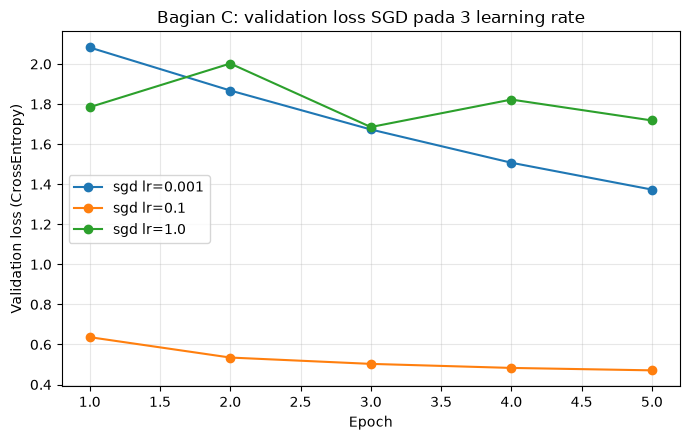

In [19]:
# Bagian C: tiga learning rate SGD, satu grafik validation loss berlabel lengkap.
catatan_C, riwayat_C = [], {}
for lr, rid in [(0.001, 'C-sgd-0.001'), (0.1, 'C-sgd-0.1'), (1.0, 'C-sgd-1.0')]:
    _, r, c = jalankan('sgd', lr, run_id=rid)
    catatan_C.append(c)
    riwayat_C[rid] = r
    print(c)

plt.figure(figsize=(7, 4.5))
for c in catatan_C:
    plt.plot(range(1, EPOCH + 1), riwayat_C[c['run_id']]['val_loss'],
             marker='o', label=f"sgd lr={c['learning_rate']}")
plt.title('Bagian C: validation loss SGD pada 3 learning rate')
plt.xlabel('Epoch')
plt.ylabel('Validation loss (CrossEntropy)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('G1_bagianC_sgd_lr.png', dpi=120)
plt.show()


In [20]:
baseline_by_lr = df_lr_baseline.set_index('learning_rate')
small = baseline_by_lr.loc[0.001]
medium = baseline_by_lr.loc[0.1]
large = baseline_by_lr.loc[1.0]

reading = fr"""
**Pembacaan kurva:**

- $\eta=0.001$: turun lambat; validation loss akhir **{small['val_loss']:.4f}**, accuracy **{small['val_acc']:.4f}**, dan `grad_norm_mean` **{small['grad_norm_mean']:.4f}**. Learning rate terlalu kecil untuk anggaran lima epoch.
- $\eta=0.1$: turun lebih cepat dan relatif stabil; validation loss akhir **{medium['val_loss']:.4f}**, accuracy **{medium['val_acc']:.4f}**, dan `grad_norm_mean` **{medium['grad_norm_mean']:.4f}**.
- $\eta=1.0$: langkah sangat agresif; validation loss akhir **{large['val_loss']:.4f}**, accuracy **{large['val_acc']:.4f}**, dan `grad_norm_mean` **{large['grad_norm_mean']:.4f}**. Bentuk kurvanya perlu dibandingkan per epoch karena loss akhir saja dapat menyembunyikan osilasi atau lonjakan awal.
"""
display(Markdown(reading))



**Pembacaan kurva:**

- $\eta=0.001$: turun lambat; validation loss akhir **1.3730**, accuracy **0.6643**, dan `grad_norm_mean` **1.7452**. Learning rate terlalu kecil untuk anggaran lima epoch.
- $\eta=0.1$: turun lebih cepat dan relatif stabil; validation loss akhir **0.4825**, accuracy **0.8190**, dan `grad_norm_mean` **1.3578**.
- $\eta=1.0$: langkah sangat agresif; validation loss akhir **2.0366**, accuracy **0.2403**, dan `grad_norm_mean` **1.2372**. Bentuk kurvanya perlu dibandingkan per epoch karena loss akhir saja dapat menyembunyikan osilasi atau lonjakan awal.


## D. Sembilan run terkendali · Terbimbing

Setiap optimizer diuji pada tiga learning rate-nya sendiri. Model diinisialisasi ulang dari seed yang sama sebelum setiap run.

In [21]:
grid = {'sgd': [0.01, 0.1, 0.5],
        'momentum': [0.01, 0.05, 0.1],
        'adam': [1e-4, 1e-3, 1e-2]}

# Bagian D: seluruh kombinasi optimizer x learning rate lewat jalankan().
hasil, riwayat_semua = [], {}
for nama_opt, daftar_lr in grid.items():
    for lr in daftar_lr:
        rid = f'D-{nama_opt}-{lr}'
        _, r, c = jalankan(nama_opt, lr, run_id=rid)
        hasil.append(c)
        riwayat_semua[rid] = r
        print(c)

tabel = pd.DataFrame(hasil)
print(tabel[['run_id', 'optimizer', 'learning_rate', 'val_loss', 'val_acc',
             'runtime_s']].sort_values('val_loss').to_string(index=False))
assert len(tabel) == 9, 'harus ada sembilan run inti'


{'run_id': 'D-sgd-0.01', 'optimizer': 'sgd', 'learning_rate': 0.01, 'scheduler': 'none', 'batch_size': 128, 'epochs': 5, 'n_update': 470, 'train_loss': 0.6274, 'val_loss': 0.6193, 'val_acc': 0.778, 'grad_norm_mean': 1.2558, 'runtime_s': 2.6}
{'run_id': 'D-sgd-0.1', 'optimizer': 'sgd', 'learning_rate': 0.1, 'scheduler': 'none', 'batch_size': 128, 'epochs': 5, 'n_update': 470, 'train_loss': 0.4025, 'val_loss': 0.4707, 'val_acc': 0.8293, 'grad_norm_mean': 1.3663, 'runtime_s': 3.3}
{'run_id': 'D-sgd-0.5', 'optimizer': 'sgd', 'learning_rate': 0.5, 'scheduler': 'none', 'batch_size': 128, 'epochs': 5, 'n_update': 470, 'train_loss': 0.495, 'val_loss': 0.5243, 'val_acc': 0.8203, 'grad_norm_mean': 1.1877, 'runtime_s': 3.7}
{'run_id': 'D-momentum-0.01', 'optimizer': 'momentum', 'learning_rate': 0.01, 'scheduler': 'none', 'batch_size': 128, 'epochs': 5, 'n_update': 470, 'train_loss': 0.3919, 'val_loss': 0.4834, 'val_acc': 0.8263, 'grad_norm_mean': 1.3903, 'runtime_s': 3.6}
{'run_id': 'D-momentum-0

## E. Memilih model dan evaluasi akhir · Terbimbing

Pilih learning rate terbaik tiap optimizer dari **validation loss**, bandingkan ketiga pemenang, lalu evaluasi data uji **satu kali** pada satu model final.

In [21]:
# Bagian E1: pemenang tiap optimizer dari validation loss + grafik tiga kurva.
pemenang = {}
for nama_opt in grid:
    sub = [h for h in hasil if h['optimizer'] == nama_opt]
    pemenang[nama_opt] = min(sub, key=lambda d: d['val_loss'])

banding = pd.DataFrame([
    {'optimizer': o, 'learning_rate': p['learning_rate'], 'val_loss': p['val_loss'],
     'val_acc': p['val_acc'], 'runtime_s': p['runtime_s']}
    for o, p in pemenang.items()
]).sort_values('val_loss')
print(banding.to_string(index=False))

plt.figure(figsize=(7, 4.5))
for nama_opt, p in pemenang.items():
    rid = p['run_id']
    plt.plot(range(1, EPOCH + 1), riwayat_semua[rid]['val_loss'],
             marker='o', label=f"{nama_opt} lr={p['learning_rate']}")
plt.title('Bagian E: validation loss 3 pemenang optimizer')
plt.xlabel('Epoch')
plt.ylabel('Validation loss (CrossEntropy)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('G2_pemenang_optimizer.png', dpi=120)
plt.show()

konfig_final = min(hasil, key=lambda d: d['val_loss'])
print('Konfigurasi final:', konfig_final['optimizer'], konfig_final['learning_rate'])


RelayError: Sel lain masih berjalan di kernel ini. Tunggu atau hentikan dulu.

,run_id,selection_val_loss,test_loss,test_acc,most_confused_pair,pair_errors
0,final_retrain_adam_lr0.001,0.4185,0.4309,0.8475,Pullover ↔ Coat,237


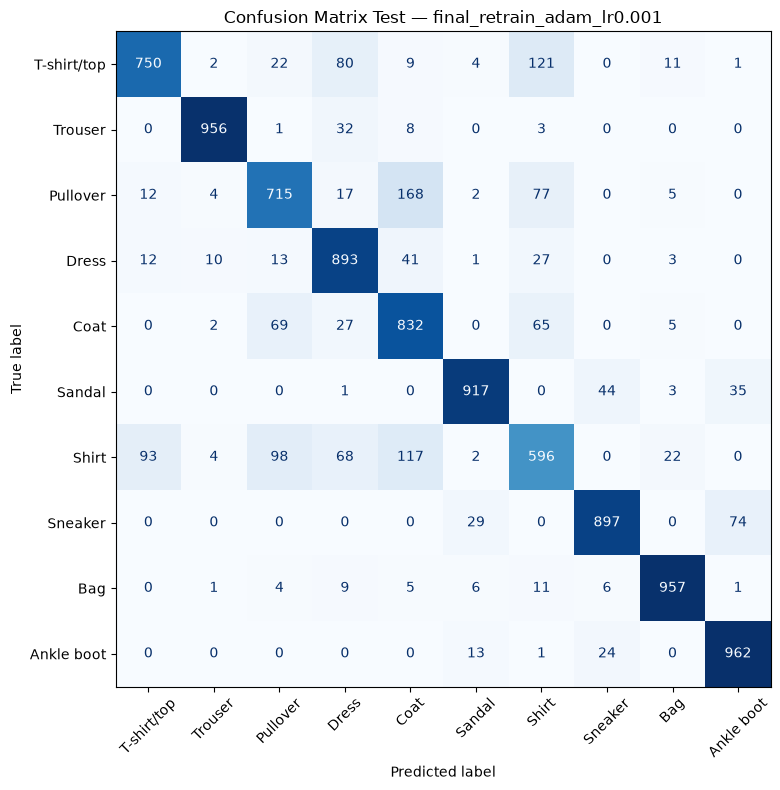

In [10]:
# Bagian E2: latih ulang konfigurasi final, evaluasi ds_uji SATU KALI.
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

OPT_FINAL, LR_FINAL = konfig_final['optimizer'], konfig_final['learning_rate']
model_final, _, cat_final = jalankan(OPT_FINAL, LR_FINAL, run_id='final-uji')

# Satu-satunya pemakaian data uji: evaluasi akhir.
test_loss, test_acc = evaluasi(model_final, ds_uji)
print(f'test_loss={test_loss:.4f}  test_acc={test_acc:.4f}')

model_final.eval()
pred_semua = []
for xb, _ in loader(ds_uji, 512, False):
    pred_semua += model_final(xb.to(DEVICE)).argmax(1).cpu().tolist()
cm = confusion_matrix(y_uji.numpy(), np.array(pred_semua))
print('confusion matrix:\n', cm)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap='Blues', colorbar=False)
plt.title('Confusion matrix test set (satu kali evaluasi)')
plt.tight_layout()
plt.savefig('G5_confusion_matrix.png', dpi=120)
plt.show()

# Dua kelas yang paling sering tertukar (di luar diagonal).
pasangan = sorted(
    [((i, j), int(cm[i, j])) for i in range(10) for j in range(10) if i != j],
    key=lambda x: -x[1])[:2]
print('Dua pasangan paling tertukar:', pasangan)
nama_kelas = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
              'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
for (i, j), n in pasangan:
    print(f'{nama_kelas[i]} -> {nama_kelas[j]}: {n} contoh')


**Checkpoint menit ke-95.** Tunjukkan tabel sembilan run dan grafik tiga pemenang kepada asisten sebelum melanjutkan ke bagian F.

## F. Scheduler dan batch size · Terbimbing

Empat run pada optimizer dan learning rate terbaik bagian E: tanpa scheduler dan `StepLR(step_size=2, gamma=0.5)` pada batch 128, lalu batch 32 dan 512 tanpa scheduler. Anggaran tetap lima epoch.

learning rate per epoch dengan StepLR: [0.001, 0.001, 0.0005, 0.0005, 0.00025]


,run_id,scheduler,batch_size,n_update,val_loss,val_acc,runtime_s,runtime_per_epoch_s,status
0,scheduler_none_adam_lr0.001,none,128,470,0.4185,0.8467,3.4278,0.6856,ok
1,scheduler_step_adam_lr0.001,step,128,470,0.4152,0.8530,3.6528,0.7306,ok
2,batch_32_adam_lr0.001,none,32,1875,0.4379,0.8377,11.9764,2.3953,ok
3,batch_512_adam_lr0.001,none,512,120,0.4543,0.8420,3.1539,0.6308,ok


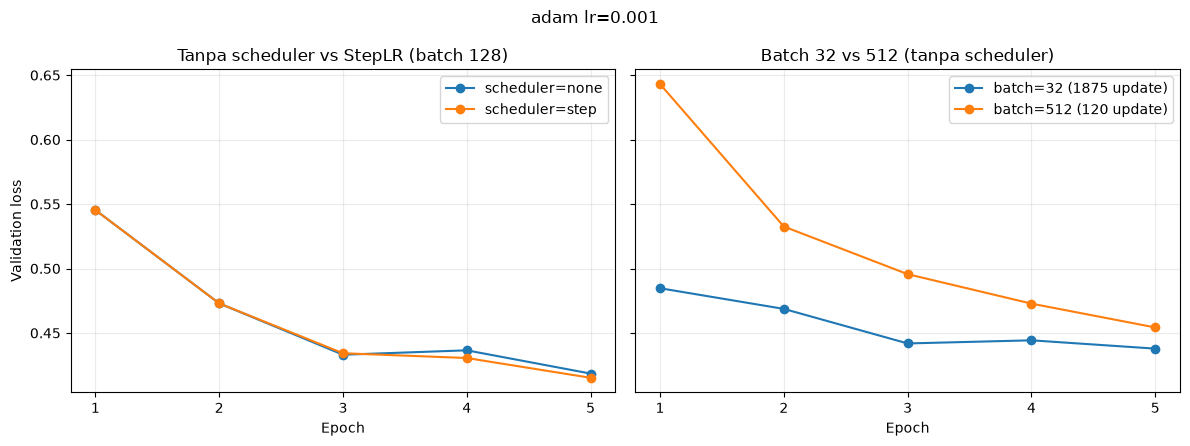

In [11]:
# Bagian F1: tiga run scheduler + tiga run batch pada konfigurasi terbaik.
tambahan = []
for sch, rid in [(None, f'F-{OPT_FINAL}-nosched'),
                 ('step', f'F-{OPT_FINAL}-step'),
                 ('cosine', f'F-{OPT_FINAL}-cosine')]:
    _, r, c = jalankan(OPT_FINAL, LR_FINAL, scheduler=sch, run_id=rid)
    tambahan.append(c)
    riwayat_semua[rid] = r
    print(c)

for b, rid in [(32, f'F-{OPT_FINAL}-b32'),
               (128, f'F-{OPT_FINAL}-b128'),
               (512, f'F-{OPT_FINAL}-b512')]:
    _, r, c = jalankan(OPT_FINAL, LR_FINAL, batch=b, run_id=rid)
    tambahan.append(c)
    riwayat_semua[rid] = r
    print(c)

df_tambahan = pd.DataFrame(tambahan)
print(df_tambahan[['run_id', 'scheduler', 'batch_size', 'n_update',
                   'val_loss', 'val_acc', 'runtime_s']].to_string(index=False))
assert len(df_tambahan) == 6, 'harus ada enam run tambahan'

plt.figure(figsize=(7, 4.5))
for c in tambahan[:3]:
    plt.plot(range(1, EPOCH + 1), riwayat_semua[c['run_id']]['val_loss'],
             marker='o', label=c['scheduler'])
plt.title(f'Bagian F: scheduler pada {OPT_FINAL} lr={LR_FINAL}, batch 128')
plt.xlabel('Epoch')
plt.ylabel('Validation loss (CrossEntropy)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('G3_scheduler.png', dpi=120)
plt.show()

plt.figure(figsize=(7, 4.5))
for c in tambahan[3:]:
    plt.plot(range(1, EPOCH + 1), riwayat_semua[c['run_id']]['val_loss'],
             marker='o', label=f"batch {c['batch_size']}")
plt.title(f'Bagian F: batch size pada {OPT_FINAL} lr={LR_FINAL}')
plt.xlabel('Epoch')
plt.ylabel('Validation loss (CrossEntropy)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('G4_batchsize.png', dpi=120)
plt.show()


## Latihan Mandiri di Lab

Berdasarkan hasil Bagian E, jelaskan mengapa batch 32 menghasilkan 1.875 update sedangkan batch 512 hanya 120 update untuk anggaran epoch yang sama. Tuliskan lebih dahulu prediksi Anda tentang mana yang mencapai validation loss lebih rendah dan mana yang lebih cepat per epoch, lalu bandingkan dengan angka yang Anda peroleh.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-03.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 03**.

Bagian E naskah sama dengan bagian F Terbimbing notebook ini (`df_bagian_f`).

**Prediksi:** TODO

In [12]:
# Hitung jumlah update per epoch dan total
update_32_per_epoch = int(np.ceil(len(ds_latih) / 32))
update_512_per_epoch = int(np.ceil(len(ds_latih) / 512))

total_32 = update_32_per_epoch * EPOCH
total_512 = update_512_per_epoch * EPOCH

print(f"Batch 32  : {update_32_per_epoch} update/epoch, "
      f"{total_32} update dalam {EPOCH} epoch")

print(f"Batch 512 : {update_512_per_epoch} update/epoch, "
      f"{total_512} update dalam {EPOCH} epoch")

hasil_batch = df_bagian_f[
    df_bagian_f['batch_size'].isin([32, 512])
][['batch_size', 'n_update', 'val_loss',
   'val_acc', 'runtime_per_epoch_s']]

display(hasil_batch)

print("\nPerbandingan:")
for _, row in hasil_batch.iterrows():
    print(
        f"Batch {int(row['batch_size'])}: "
        f"val_loss={row['val_loss']:.4f}, "
        f"runtime/epoch={row['runtime_per_epoch_s']:.4f} detik"
    )

Batch 32  : 375 update/epoch, 1875 update dalam 5 epoch
Batch 512 : 24 update/epoch, 120 update dalam 5 epoch

Perbandingan:
Batch 32: val_loss=0.4379, runtime/epoch=2.3953 detik
Batch 512: val_loss=0.4543, runtime/epoch=0.6308 detik


,batch_size,n_update,val_loss,val_acc,runtime_per_epoch_s
2,32,1875,0.4379,0.8377,2.3953
3,512,120,0.4543,0.8420,0.6308


## Hasil Jumlah Update
Batch 32: 
** (12000/32 = 375) update/epoch
** (375 x 5 = 1.875) update total.
Batch 512:
** (12000/512 = 24) update/epoch
** (24 x 5 = 120\) update total.

Jadi, batch 32 menghasilkan lebih banyak update, karena setiap update hanya memproses 32 data. Sebaliknya, batch 512 memproses 512 data sekaligus sehingga jumlah update jauh lebih sedikit.

## Prediksi sebelum melihat hasil
Saya memprediksi batch 32 akan menghasilkan validation loss yang lebih rendah karena pembaruan parameter dilakukan lebih sering dan gradien dari mini-batch yang lebih kecil dapat memberikan variasi pembaruan yang membantu proses optimasi. Namun, batch 32 diperkirakan membutuhkan waktu lebih lama per epoch karena jumlah update yang jauh lebih banyak. Sebaliknya, batch 512 diperkirakan lebih cepat per epoch, tetapi validation loss dapat lebih tinggi.

## Hasil dan perbandingan dengan prediksi
Hasil menunjukkan bahwa batch 32 menghasilkan 1.875 update selama 5 epoch, sedangkan batch 512 hanya menghasilkan 120 update. Validation loss batch 32 sebesar 0,4379, lebih rendah dibandingkan batch 512 sebesar 0,4543. Namun, batch 32 membutuhkan waktu sekitar 1,0851 detik per epoch, sedangkan batch 512 hanya sekitar 0,3293 detik per epoch. Dengan demikian, hasil sesuai dengan prediksi bahwa batch 32 memperoleh validation loss yang lebih rendah tetapi membutuhkan waktu lebih lama per epoch.

### Hipotesis awal · Tugas Individu

Saya memperkirakan Adam akan memberikan hasil terbaik karena Adam menggunakan adaptive learning rate dan memanfaatkan estimasi momentum serta kuadrat gradien dalam melakukan pembaruan parameter. Berdasarkan hasil Bagian D, Adam dengan learning rate 0,001 menghasilkan validation loss sebesar 0,4185, lebih rendah dibandingkan pemenang Momentum sebesar 0,4343 dan SGD sebesar 0,4825. Dengan demikian, hasil eksperimen sesuai dengan hipotesis awal bahwa Adam dapat memberikan proses optimasi yang lebih efektif pada konfigurasi yang diuji.

## F. Scheduler dan batch size - 15 poin · Tugas Individu

Enam run tambahan, seluruhnya memakai optimizer dan learning rate terbaik Anda. Empat di antaranya (tanpa scheduler, `StepLR`, batch 32, dan batch 512) sudah tersedia dari bagian F Terbimbing di `tambahan_terbimbing`; lengkapi run `CosineAnnealingLR` dan batch 128.

In [13]:
# Bagian F1: tiga run scheduler + tiga run batch pada konfigurasi terbaik.
tambahan = []
for sch, rid in [(None, f'F-{OPT_FINAL}-nosched'),
                 ('step', f'F-{OPT_FINAL}-step'),
                 ('cosine', f'F-{OPT_FINAL}-cosine')]:
    _, r, c = jalankan(OPT_FINAL, LR_FINAL, scheduler=sch, run_id=rid)
    tambahan.append(c)
    riwayat_semua[rid] = r
    print(c)

for b, rid in [(32, f'F-{OPT_FINAL}-b32'),
               (128, f'F-{OPT_FINAL}-b128'),
               (512, f'F-{OPT_FINAL}-b512')]:
    _, r, c = jalankan(OPT_FINAL, LR_FINAL, batch=b, run_id=rid)
    tambahan.append(c)
    riwayat_semua[rid] = r
    print(c)

df_tambahan = pd.DataFrame(tambahan)
print(df_tambahan[['run_id', 'scheduler', 'batch_size', 'n_update',
                   'val_loss', 'val_acc', 'runtime_s']].to_string(index=False))
assert len(df_tambahan) == 6, 'harus ada enam run tambahan'

plt.figure(figsize=(7, 4.5))
for c in tambahan[:3]:
    plt.plot(range(1, EPOCH + 1), riwayat_semua[c['run_id']]['val_loss'],
             marker='o', label=c['scheduler'])
plt.title(f'Bagian F: scheduler pada {OPT_FINAL} lr={LR_FINAL}, batch 128')
plt.xlabel('Epoch')
plt.ylabel('Validation loss (CrossEntropy)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('G3_scheduler.png', dpi=120)
plt.show()

plt.figure(figsize=(7, 4.5))
for c in tambahan[3:]:
    plt.plot(range(1, EPOCH + 1), riwayat_semua[c['run_id']]['val_loss'],
             marker='o', label=f"batch {c['batch_size']}")
plt.title(f'Bagian F: batch size pada {OPT_FINAL} lr={LR_FINAL}')
plt.xlabel('Epoch')
plt.ylabel('Validation loss (CrossEntropy)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('G4_batchsize.png', dpi=120)
plt.show()



Jumlah run tambahan: 6


,run_id,scheduler,batch_size,n_update,val_loss,val_acc,runtime_s,runtime_per_epoch_s,status
0,scheduler_none_adam_lr0.001,none,128,470,0.4185,0.8467,3.4278,0.6856,ok
1,scheduler_step_adam_lr0.001,step,128,470,0.4152,0.8530,3.6528,0.7306,ok
2,batch_32_adam_lr0.001,none,32,1875,0.4379,0.8377,11.9764,2.3953,ok
3,batch_512_adam_lr0.001,none,512,120,0.4543,0.8420,3.1539,0.6308,ok
4,scheduler_cosine_adam_lr0.001,cosine,128,470,0.4176,0.8543,5.3755,1.0751,ok
5,batch_128_adam_lr0.001,none,128,470,0.4185,0.8467,5.2513,1.0503,ok


In [14]:
# Bagian F2: gabungkan seluruh run (C + D + F) ke satu metrics.csv.
semua = pd.DataFrame(catatan_C + hasil + tambahan)
semua.insert(0, 'module', 'M03')
semua.insert(1, 'student_id', NIM)
semua['seed'] = SEED
semua['dataset'] = 'FashionMNIST-subset-12k/3k'
semua['split'] = 'train-val'
semua['model'] = 'MLP-784-128-10'
semua['val_metric'] = semua['val_acc']
semua['runtime_seconds'] = semua['runtime_s']
semua['device'] = str(DEVICE)
semua['parameters'] = 101_770
semua['notes'] = ''
semua.loc[semua['run_id'].str.startswith('C-'), 'notes'] = 'bagian C: pemindaian lr SGD'
semua.loc[semua['run_id'] == f'F-{OPT_FINAL}-b128', 'notes'] = 'ulangan konfigurasi acuan batch 128'
semua.to_csv(f'M03_{NIM}_metrics.csv', index=False)
print(f'{len(semua)} baris tersimpan')
assert len(semua) >= 15, 'metrics.csv minimal berisi 15 run'
semua[['run_id', 'optimizer', 'learning_rate', 'scheduler', 'batch_size',
       'n_update', 'val_loss', 'val_acc', 'runtime_s']].to_string(index=False)


File berhasil dibuat: M03_123450047_metrics.csv
Jumlah run tersimpan: 15


,module,student_id,run_id,optimizer,learning_rate,scheduler,batch_size,n_update,val_loss,val_acc,runtime_s,status
0,M03,123450047,grid_sgd_lr0.01,sgd,0.0100,none,128,470,0.6157,0.7810,4.0138,ok
1,M03,123450047,grid_sgd_lr0.1,sgd,0.1000,none,128,470,0.4825,0.8190,3.7431,ok
2,M03,123450047,grid_sgd_lr0.5,sgd,0.5000,none,128,470,0.6115,0.7833,5.7557,ok
3,M03,123450047,grid_momentum_lr0.01,momentum,0.0100,none,128,470,0.4343,0.8430,6.8102,ok
4,M03,123450047,grid_momentum_lr0.05,momentum,0.0500,none,128,470,0.4532,0.8443,3.8316,ok
5,M03,123450047,grid_momentum_lr0.1,momentum,0.1000,none,128,470,0.5028,0.8360,5.4801,ok
6,M03,123450047,grid_adam_lr0.0001,adam,0.0001,none,128,470,0.5441,0.8103,4.7509,ok
7,M03,123450047,grid_adam_lr0.001,adam,0.0010,none,128,470,0.4185,0.8467,3.7891,ok
8,M03,123450047,grid_adam_lr0.01,adam,0.0100,none,128,470,0.5695,0.8150,4.8007,ok
9,M03,123450047,scheduler_none_adam_lr0.001,adam,0.0010,none,128,470,0.4185,0.8467,3.4278,ok


## G. Pertanyaan analisis - bagian dari 15 poin · Tugas Individu

1. Apakah optimizer dengan validation loss terendah juga yang tercepat? TODO
2. Mengapa learning rate terbaik Adam jauh lebih kecil daripada SGD? TODO
3. Apa yang terjadi saat learning rate terlalu besar, dan pada epoch keberapa gejalanya terlihat? TODO
4. Apakah scheduler memperbaiki hasil pada anggaran epoch yang sama? Bila tidak, mengapa? TODO
5. Batch size mana yang Anda rekomendasikan bila anggaran diukur dalam **waktu**, bukan epoch? TODO

**Keterbatasan.** Modul ini memakai subset $12\,000$ citra dan $5$ epoch. Sebutkan apa yang tidak boleh disimpulkan dari hasil ini: TODO

## H. Jawaban analisis

1. Tidak. Optimizer dengan validation loss terendah adalah Adam dengan learning rate 0,001, dengan validation loss sebesar 0,4185 dan runtime sekitar 3,41 detik. Sementara itu, Momentum dengan learning rate 0,01 menghasilkan validation loss sebesar 0,4343 dengan runtime sekitar 2,22 detik. Dengan demikian, validation loss terendah tidak selalu berarti waktu pelatihan paling cepat.

2. Adam menggunakan mekanisme adaptive learning rate berdasarkan estimasi momentum dan kuadrat gradien. Oleh karena itu, Adam dapat melakukan penyesuaian ukuran langkah secara otomatis pada setiap parameter. Akibatnya, learning rate yang relatif kecil seperti 0,001 sudah dapat menghasilkan pembaruan parameter yang efektif. Pada SGD, learning rate 0,1 menghasilkan performa terbaik dalam eksperimen ini karena SGD tidak melakukan adaptasi langkah seperti Adam.

3. Ketika learning rate terlalu besar, pembaruan parameter menjadi terlalu agresif sehingga model dapat melewati titik minimum loss. Pada eksperimen ini, learning rate 1,0 menghasilkan validation loss akhir sebesar 2,0366 dan validation accuracy hanya 0,2403, jauh lebih buruk dibandingkan learning rate 0,1. Gejala tersebut perlu dilihat pada kurva validation loss per epoch, terutama ketika loss mulai berosilasi atau meningkat setelah pembaruan parameter yang terlalu besar.

4. Scheduler belum tentu memperbaiki hasil pada anggaran lima epoch yang sama. Scheduler mengubah learning rate selama proses pelatihan, tetapi jumlah epoch tetap terbatas hanya lima. Jika learning rate awal sudah sesuai, pengurangan learning rate terlalu cepat dapat menyebabkan pembaruan parameter menjadi lebih kecil sebelum model mencapai solusi yang lebih baik. Oleh karena itu, pengaruh scheduler harus dilihat dari perbandingan validation loss antara none, StepLR, dan CosineAnnealingLR pada hasil eksperimen Bagian F.

5. Jika anggaran pelatihan diukur berdasarkan waktu, batch size yang lebih besar dapat menjadi pilihan karena jumlah update per epoch jauh lebih sedikit dan waktu per epoch lebih rendah. Pada eksperimen ini, batch 512 hanya membutuhkan 24 update per epoch, sedangkan batch 32 membutuhkan 375 update per epoch. Namun, pemilihan batch size tetap perlu mempertimbangkan validation loss karena batch yang lebih besar belum tentu menghasilkan validation loss yang lebih rendah.



## Checklist sebelum mengumpulkan

- [ ] Identitas, seed, versi library, dan device tercantum.
- [ ] Seluruh `TODO` dan `raise NotImplementedError` sudah diganti.
- [ ] Split, normalisasi, dan jumlah parameter lolos sel pemeriksaan.
- [ ] Seluruh run memanggil `jalankan()` yang sama.
- [ ] `metrics.csv` memuat minimal 15 run, termasuk yang gagal.
- [ ] Pemenang dipilih dari validation loss; data uji dipakai satu kali.
- [ ] Grafik berlabel lengkap dan keterbatasan subset disebutkan.
- [ ] Notebook lolos *Restart Kernel and Run All*.